## Step 02: Load the Image

In [1]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

In [2]:
image = cv.imread("car.jpg")

if image is None:
    raise FileNotFoundError("Image not found: car.jpg")

print("Image shape:", image.shape)
print("Image data type:", image.dtype)

Image shape: (3413, 1920, 3)
Image data type: uint8


## Step 03: Inspecting the Image


In [3]:
height, width, channels = image.shape

print("Height (rows):", height)
print("Width (columns):", width)
print("Number of channels:", channels)

center_row = height // 2
center_col = width // 2

print("Top-left pixel [0, 0] (B, G, R):", image[0, 0])
print(f"Center pixel [{center_row}, {center_col}] (B, G, R):", image[center_row, center_col])

print("Global minimum value:", image.min())
print("Global maximum value:", image.max())

channel_names = ["Blue", "Green", "Red"]
for i, name in enumerate(channel_names):
    print(name, "channel -> min:", image[:, :, i].min(), ", max:", image[:, :, i].max())

Height (rows): 3413
Width (columns): 1920
Number of channels: 3
Top-left pixel [0, 0] (B, G, R): [171 130  85]
Center pixel [1706, 960] (B, G, R): [ 67 127 127]
Global minimum value: 0
Global maximum value: 255
Blue channel -> min: 0 , max: 255
Green channel -> min: 0 , max: 255
Red channel -> min: 0 , max: 255


## Step 04: Converting Colors and Splitting Channels


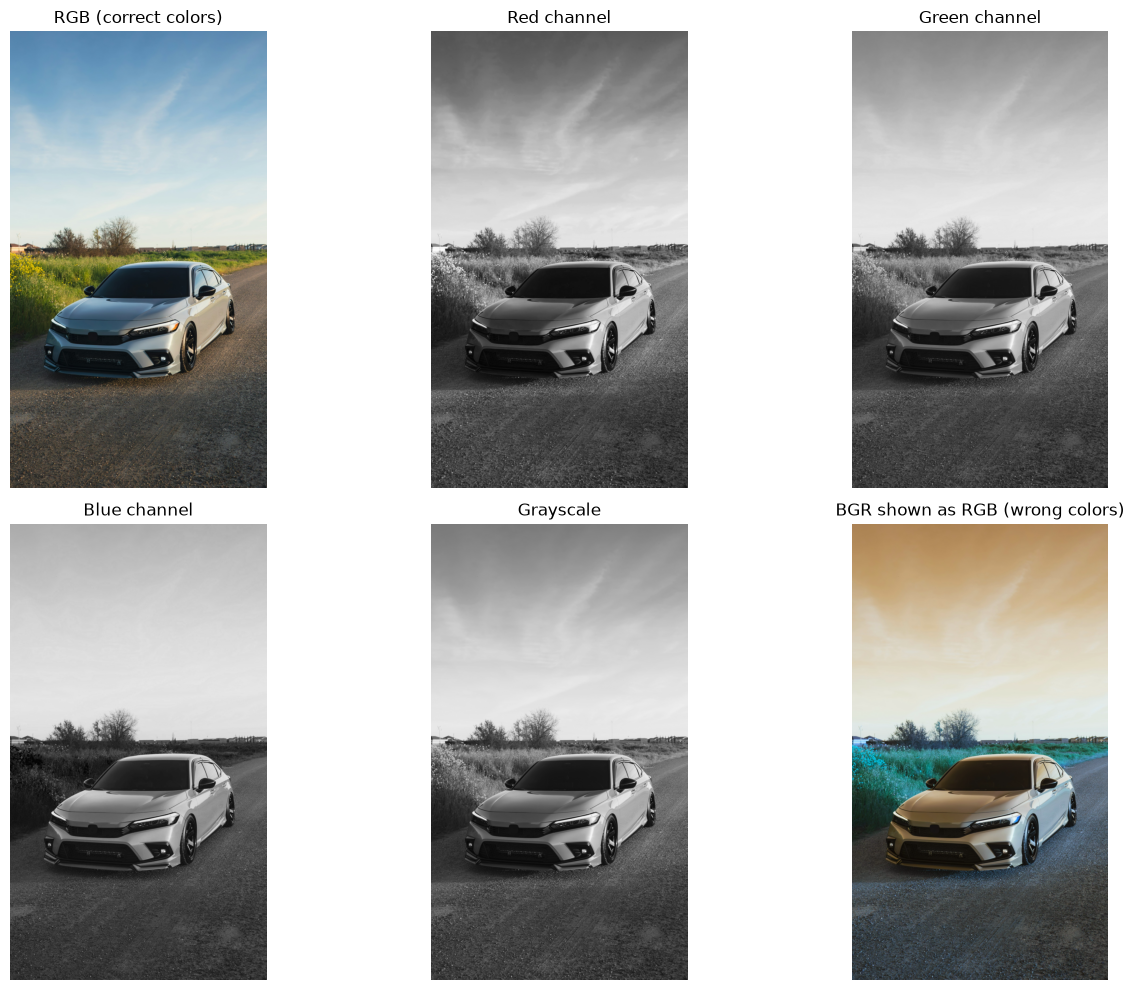

In [4]:
image_rgb = cv.cvtColor(image, cv.COLOR_BGR2RGB)
gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)

red = image_rgb[:, :, 0]
green = image_rgb[:, :, 1]
blue = image_rgb[:, :, 2]

fig, axes = plt.subplots(2, 3, figsize=(14, 10))

axes[0, 0].imshow(image_rgb)
axes[0, 0].set_title("RGB (correct colors)")

axes[0, 1].imshow(red, cmap="gray")
axes[0, 1].set_title("Red channel")

axes[0, 2].imshow(green, cmap="gray")
axes[0, 2].set_title("Green channel")

axes[1, 0].imshow(blue, cmap="gray")
axes[1, 0].set_title("Blue channel")

axes[1, 1].imshow(gray, cmap="gray")
axes[1, 1].set_title("Grayscale")

axes[1, 2].imshow(image)
axes[1, 2].set_title("BGR shown as RGB (wrong colors)")

for ax in axes.ravel():
    ax.axis("off")

plt.tight_layout()
plt.show()

In [5]:
r, g, b = image_rgb[center_row, center_col]
print("Center pixel RGB:", (int(r), int(g), int(b)))
print("Center pixel HEX:", "#{:02X}{:02X}{:02X}".format(int(r), int(g), int(b)))

Center pixel RGB: (127, 127, 67)
Center pixel HEX: #7F7F43


## Step 05: Crop, Resize and Save


In [6]:
# crop and resize
y_start = center_row - 50
x_start = center_col - 50

crop = image_rgb[y_start:y_start + 100, x_start:x_start + 100]
print("Crop shape:", crop.shape)

resized = cv.resize(crop, (200, 200), interpolation=cv.INTER_LINEAR)
print("Resized shape:", resized.shape)

Crop shape: (100, 100, 3)
Resized shape: (200, 200, 3)


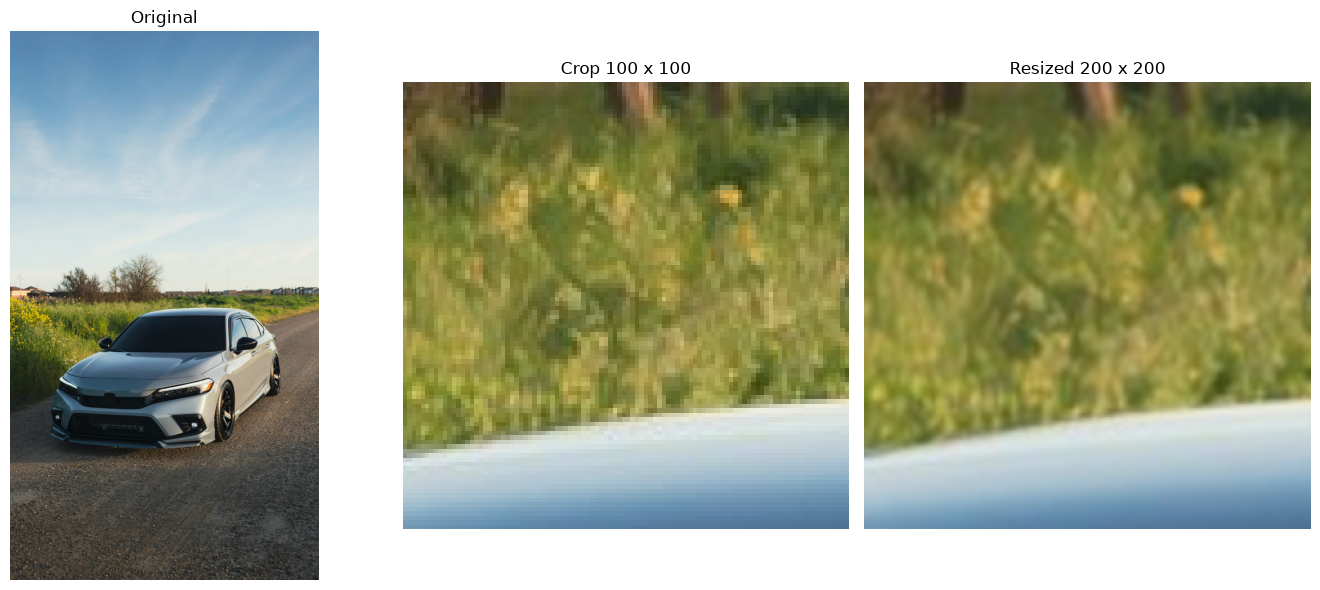

In [7]:
# shown all three side by side
fig, axes = plt.subplots(1, 3, figsize=(14, 6))

axes[0].imshow(image_rgb)
axes[0].set_title("Original")

axes[1].imshow(crop)
axes[1].set_title("Crop 100 x 100")

axes[2].imshow(resized)
axes[2].set_title("Resized 200 x 200")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [8]:
# save the resized image
resized_bgr = cv.cvtColor(resized, cv.COLOR_RGB2BGR)
saved = cv.imwrite("resized_crop.png", resized_bgr)
print("resized_crop.png saved successfully:", saved)

resized_crop.png saved successfully: True


## Step 06: Grayscale Histogram


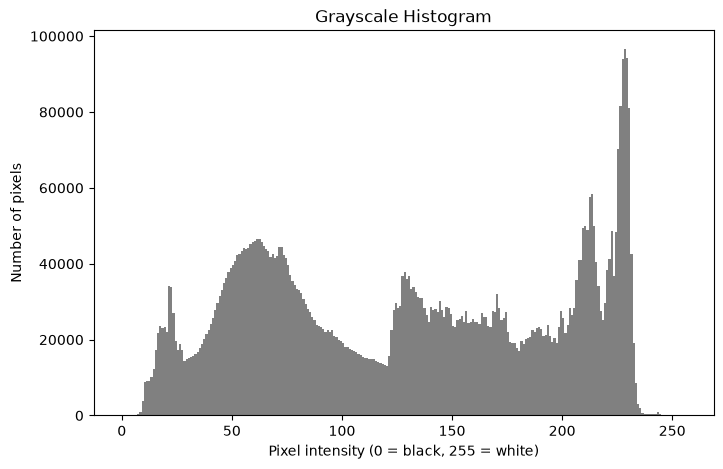

In [9]:
# Plotting and saving the histogram
plt.figure(figsize=(8, 5))
plt.hist(gray.flatten(), bins=256, range=(0, 256), color="gray")
plt.title("Grayscale Histogram")
plt.xlabel("Pixel intensity (0 = black, 255 = white)")
plt.ylabel("Number of pixels")
plt.savefig("grayscale_histogram.png", dpi=150, bbox_inches="tight")
plt.show()

In [10]:
# mean and median values
print("Mean gray value:", round(float(gray.mean()), 2))
print("Median gray value:", float(np.median(gray)))

Mean gray value: 129.33
Median gray value: 130.0


## Step 7: Demonstrating Bit Depth

In [11]:
# 8-bit horizontal gradient: values 0 to 255, height 100, width 256
gradient = np.tile(np.arange(256, dtype=np.uint8), (100, 1))

def quantize(img, bits):
    levels = 2 ** bits
    step = 256 // levels
    return ((img // step) * (255 // (levels - 1))).astype(np.uint8)

# Quantizing the gradient 
g4 = quantize(gradient, 4)
g2 = quantize(gradient, 2)
g1 = quantize(gradient, 1)

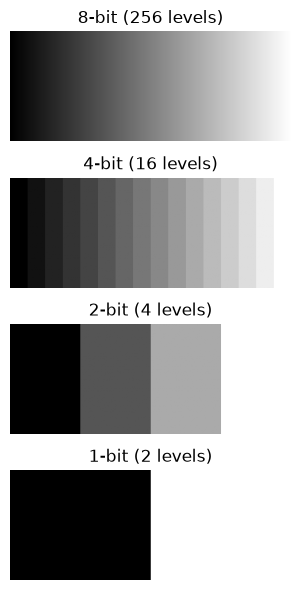

In [12]:
# showing all four quantized gradients 
fig, axes = plt.subplots(4, 1, figsize=(8, 6))

images = [gradient, g4, g2, g1]
titles = ["8-bit (256 levels)", "4-bit (16 levels)", "2-bit (4 levels)", "1-bit (2 levels)"]

for ax, img, title in zip(axes, images, titles):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [13]:
# Counting the distinct brightness levels
print("8-bit unique values:", len(np.unique(gradient)))
print("4-bit unique values:", len(np.unique(g4)))
print("2-bit unique values:", len(np.unique(g2)))
print("1-bit unique values:", len(np.unique(g1)))

8-bit unique values: 256
4-bit unique values: 16
2-bit unique values: 4
1-bit unique values: 2
